# EV Charging Patterns: Data Cleaning, Exploration and Charger-Type Comparison
**Course:** CSE 2103 | **Team:** 09 |

**Members:** 
1. Sunanda Mishra 
2. Akhila
3. Kaustubh Sharma       
4. Pranav Reddy

**Objectives**
1. Clean the charging records.
2. Describe charging duration, energy consumption and cost across charger categories (Level 1, Level 2, DC Fast Charger) and visualise distributions and relationships.
3. **CDA:** test whether mean charging duration differs between charger types.
4. **ARM:** identify frequently occurring combinations of charging characteristics (Apriori).


## 0. Setup

In [1]:
import json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from mlxtend.frequent_patterns import apriori, association_rules

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
import os; os.makedirs('figs', exist_ok=True)

DATA_PATH = 'ev_charging_patterns.csv' 
ORDER = ['Level 1', 'Level 2', 'DC Fast Charger']
PAL = {'Level 1': '#4C78A8', 'Level 2': '#F58518', 'DC Fast Charger': '#54A24B'}
R = {}   # results store (used to write the report)

## 1. Data loading and initial inspection

In [2]:
raw = pd.read_csv(DATA_PATH)
print('Shape:', raw.shape)
display(raw.head())
raw.info()
R['n_raw'], R['p_raw'] = raw.shape

Shape: (1320, 20)


,User ID,Vehicle Model,Battery Capacity (kWh),Charging Station ID,Charging Station Location,Charging Start Time,Charging End Time,Energy Consumed (kWh),Charging Duration (hours),Charging Rate (kW),Charging Cost (USD),Time of Day,Day of Week,State of Charge (Start %),State of Charge (End %),Distance Driven (since last charge) (km),Temperature (°C),Vehicle Age (years),Charger Type,User Type
0,User_1,BMW i3,108.463007,Station_391,Houston,2024-01-01 00:00:00,2024-01-01 00:39:00,60.712346,0.591363,36.389181,13.087717,Evening,Tuesday,29.371576,86.119962,293.602111,27.947953,2.0,DC Fast Charger,Commuter
1,User_2,Hyundai Kona,100.000000,Station_428,San Francisco,2024-01-01 01:00:00,2024-01-01 03:01:00,12.339275,3.133652,30.677735,21.128448,Morning,Monday,10.115778,84.664344,112.112804,14.311026,3.0,Level 1,Casual Driver
2,User_3,Chevy Bolt,75.000000,Station_181,San Francisco,2024-01-01 02:00:00,2024-01-01 04:48:00,19.128876,2.452653,27.513593,35.667270,Morning,Thursday,6.854604,69.917615,71.799253,21.002002,2.0,Level 2,Commuter
3,User_4,Hyundai Kona,50.000000,Station_327,Houston,2024-01-01 03:00:00,2024-01-01 06:42:00,79.457824,1.266431,32.882870,13.036239,Evening,Saturday,83.120003,99.624328,199.577785,38.316313,1.0,Level 1,Long-Distance Traveler
4,User_5,Hyundai Kona,50.000000,Station_108,Los Angeles,2024-01-01 04:00:00,2024-01-01 05:46:00,19.629104,2.019765,10.215712,10.161471,Morning,Saturday,54.258950,63.743786,203.661847,-7.834199,1.0,Level 1,Long-Distance Traveler


<class 'pandas.DataFrame'>
RangeIndex: 1320 entries, 0 to 1319
Data columns (total 20 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   User ID                                   1320 non-null   str    
 1   Vehicle Model                             1320 non-null   str    
 2   Battery Capacity (kWh)                    1320 non-null   float64
 3   Charging Station ID                       1320 non-null   str    
 4   Charging Station Location                 1320 non-null   str    
 5   Charging Start Time                       1320 non-null   str    
 6   Charging End Time                         1320 non-null   str    
 7   Energy Consumed (kWh)                     1254 non-null   float64
 8   Charging Duration (hours)                 1320 non-null   float64
 9   Charging Rate (kW)                        1254 non-null   float64
 10  Charging Cost (USD)                       1320 

In [3]:
print('Missing values per column:'); print(raw.isna().sum()[raw.isna().sum() > 0])
print('\nExact duplicate rows:', raw.duplicated().sum())
print('Duplicate User IDs   :', raw['User ID'].duplicated().sum())
display(raw.describe().T)

Missing values per column:
Energy Consumed (kWh)                       66
Charging Rate (kW)                          66
Distance Driven (since last charge) (km)    66
dtype: int64

Exact duplicate rows: 0
Duplicate User IDs   : 0


,count,mean,std,min,25%,50%,75%,max
Battery Capacity (kWh),1320.0,74.534692,20.626914,1.532807,62.000000,75.000000,85.000000,193.003074
Energy Consumed (kWh),1254.0,42.642894,22.411705,0.045772,23.881193,42.691405,61.206218,152.238758
Charging Duration (hours),1320.0,2.269377,1.061037,0.095314,1.397623,2.258136,3.112806,7.635145
Charging Rate (kW),1254.0,25.963003,14.011326,1.472549,13.856583,25.603799,37.502998,97.342255
Charging Cost (USD),1320.0,22.551352,10.751494,0.234317,13.368141,22.076360,31.646044,69.407743
State of Charge (Start %),1320.0,49.130012,24.074134,2.325959,27.786903,48.241771,69.277921,152.489761
State of Charge (End %),1320.0,75.141590,17.080580,7.604224,62.053266,75.682496,88.201370,177.708666
Distance Driven (since last charge) (km),1254.0,153.596788,86.004987,0.862361,79.445335,152.259867,226.073284,398.364775
Temperature (°C),1320.0,15.263591,14.831216,-10.724770,2.800664,14.630846,27.981810,73.169588
Vehicle Age (years),1320.0,3.612843,2.309824,0.000000,2.000000,4.000000,6.000000,11.688592


## 2. Data preprocessing
Steps: (a) type/format corrections, (b) duplicates, (c) missing values, (d) invalid / impossible values (removed), (e) suspicious-but-retained records (flagged), (f) final dataset.

In [4]:
df = raw.copy()
rename = {'Charging Duration (hours)':'Duration_h', 'Energy Consumed (kWh)':'Energy_kWh',
          'Charging Cost (USD)':'Cost_USD', 'Charging Rate (kW)':'Rate_kW',
          'Battery Capacity (kWh)':'Battery_kWh', 'State of Charge (Start %)':'SoC_start',
          'State of Charge (End %)':'SoC_end', 'Distance Driven (since last charge) (km)':'Distance_km',
          'Temperature (°C)':'Temp_C', 'Vehicle Age (years)':'VehAge', 'Charger Type':'Charger',
          'Charging Station Location':'City', 'Vehicle Model':'Model', 'User Type':'UserType',
          'Time of Day':'TimeOfDay', 'Day of Week':'Day'}
df = df.rename(columns=rename)

# (a) type / format corrections
df['Start'] = pd.to_datetime(df['Charging Start Time'])
df['End']   = pd.to_datetime(df['Charging End Time'])
for c in ['Charger','City','Model','UserType','TimeOfDay','Day']:
    df[c] = df[c].str.strip()
df['Charger'] = pd.Categorical(df['Charger'], categories=ORDER, ordered=True)
df['VehAge'] = df['VehAge'].round().astype(int)        
print('Data types fixed. Charger categories:', list(df['Charger'].cat.categories))

Data types fixed. Charger categories: ['Level 1', 'Level 2', 'DC Fast Charger']


In [5]:
# (b) duplicates
R['dups'] = int(df.duplicated().sum())
print('Duplicate rows removed:', R['dups'])
df = df.drop_duplicates()

# (c) missing values: Energy, Rate, Distance each have ~5% missing, scattered over different rows
miss = df[['Energy_kWh','Rate_kW','Distance_km']].isna().sum()
R['missing'] = {k:int(v) for k,v in miss.items()}
print(miss)
for c in ['Energy_kWh','Rate_kW','Distance_km']:
    df[c+'_imputed'] = df[c].isna()
    df[c] = df[c].fillna(df.groupby('Charger', observed=True)[c].transform('median'))
print('Remaining missing:', int(df[['Energy_kWh','Rate_kW','Distance_km']].isna().sum().sum()))

Duplicate rows removed: 0
Energy_kWh     66
Rate_kW        66
Distance_km    66
dtype: int64
Remaining missing: 0


In [6]:
# (d) impossible / implausible values: removed
rules = {
 'SoC > 100 %'                       : (df.SoC_start > 100) | (df.SoC_end > 100),
 'Temperature > 45 C (US cities)'    : df.Temp_C > 45,
 'Battery capacity < 20 or > 150 kWh': (df.Battery_kWh < 20) | (df.Battery_kWh > 150),
}
bad = pd.Series(False, index=df.index)
R['invalid'] = {}
for k, m in rules.items():
    print(f'{k:38s}: {int(m.sum()):4d} rows'); R['invalid'][k] = int(m.sum()); bad |= m
R['invalid_total'] = int(bad.sum())
print('Total removed (union):', R['invalid_total'])
df = df[~bad].copy()
print('Rows after removal:', len(df))

SoC > 100 %                           :   32 rows
Temperature > 45 C (US cities)        :    8 rows
Battery capacity < 20 or > 150 kWh    :   16 rows
Total removed (union): 55
Rows after removal: 1265


In [7]:
# (e) suspicious but retained: flagged
df['flag_soc_drop']   = df.SoC_end < df.SoC_start                       # SoC fell during a charge
df['flag_energy_gt_cap'] = df.Energy_kWh > df.Battery_kWh               # more energy than battery size
df['ts_hours'] = (df.End - df.Start).dt.total_seconds()/3600
df['flag_time_mismatch'] = (df.ts_hours - df.Duration_h).abs() > 0.25   # timestamps disagree with duration
q1, q3 = df.Duration_h.quantile([.25,.75]); iqr = q3-q1
df['flag_dur_outlier'] = (df.Duration_h < q1-1.5*iqr) | (df.Duration_h > q3+1.5*iqr)
hr = df.Start.dt.hour
exp = pd.cut(hr, [-1,5,11,17,20,23], labels=['Night','Morning','Afternoon','Evening','Night2']).astype(str).replace('Night2','Night')
df['flag_tod_mismatch'] = exp != df.TimeOfDay
flags = [c for c in df.columns if c.startswith('flag_')]
R['flags'] = {c:int(df[c].sum()) for c in flags}
print(df[flags].sum())
df['strict_ok'] = ~df[['flag_soc_drop','flag_energy_gt_cap']].any(axis=1)   # timestamp mismatch affects ~87% of rows : reported as a dataset limitation, not used to filter
R['strict_n'] = int(df.strict_ok.sum())
print('Strict subset (no SoC-drop / energy>capacity):', R['strict_n'])

flag_soc_drop          256
flag_energy_gt_cap     175
flag_time_mismatch    1096
flag_dur_outlier         5
flag_tod_mismatch      961
dtype: int64
Strict subset (no SoC-drop / energy>capacity): 874


In [8]:
# (f) final dataset
df = df.reset_index(drop=True)
R['n_clean'] = len(df)
R['n_vars_final'] = df.shape[1]
summary = pd.DataFrame({'Before': [raw.shape[0], int(raw.isna().sum().sum()), int(raw.duplicated().sum())],
                        'After':  [len(df), int(df[['Energy_kWh','Rate_kW','Distance_km']].isna().sum().sum()), 0]},
                       index=['Records','Missing cells','Duplicate rows'])
display(summary)
print(df.Charger.value_counts())
df.to_csv('ev_charging_clean.csv', index=False)

,Before,After
Records,1320,1265
Missing cells,198,0
Duplicate rows,0,0


Charger
Level 1            442
DC Fast Charger    413
Level 2            410
Name: count, dtype: int64


## 3. Exploratory Data Analysis

### 3.1 Descriptive statistics

In [9]:
core = ['Duration_h','Energy_kWh','Cost_USD']
desc = df[core].agg(['count','mean','median','std','min','max']).T.round(2)
display(desc)
R['desc'] = desc.to_dict('index')

by = df.groupby('Charger', observed=True)[core].agg(['count','mean','median','std']).round(2)
display(by)
R['by'] = {c:{m:{k:float(by.loc[c,(m,k)]) for k in ['count','mean','median','std']} for m in core} for c in ORDER}

for c in ['City','UserType','TimeOfDay','Model','Day']:
    print(); print((df[c].value_counts(normalize=True)*100).round(1).to_string())

,count,mean,median,std,min,max
Duration_h,1265.0,2.26,2.24,1.05,0.10,6.77
Energy_kWh,1265.0,42.65,42.29,21.94,0.05,152.24
Cost_USD,1265.0,22.60,22.21,10.75,0.23,69.41


Duration_h                    Energy_kWh                      Cost_USD                     
                     count  mean median   std      count   mean median    std    count   mean median    std
Charger                                                                                                    
Level 1                442  2.22   2.18  1.06        442  41.71  42.29  21.99      442  21.63  20.85  10.32
Level 2                410  2.29   2.30  1.04        410  45.21  46.09  21.34      410  22.41  21.63  10.68
DC Fast Charger        413  2.27   2.26  1.05        413  41.11  40.25  22.30      413  23.83  24.00  11.17


City
Los Angeles      22.5
San Francisco    20.3
Houston          19.9
New York         19.1
Chicago          18.2

UserType
Commuter                  35.7
Long-Distance Traveler    33.4
Casual Driver             30.9

TimeOfDay
Evening      27.4
Morning      25.8
Night        23.6
Afternoon    23.3

Model
Tesla Model 3    21.4
Hyundai Kona     20.0
Chevy Bolt       19.7
BMW i3           19.4
Nissan Leaf      19.4

Day
Saturday     15.7
Wednesday    14.9
Tuesday      14.8
Sunday       14.7
Friday       14.2
Monday       14.0
Thursday     11.7


### 3.2 Visual analysis

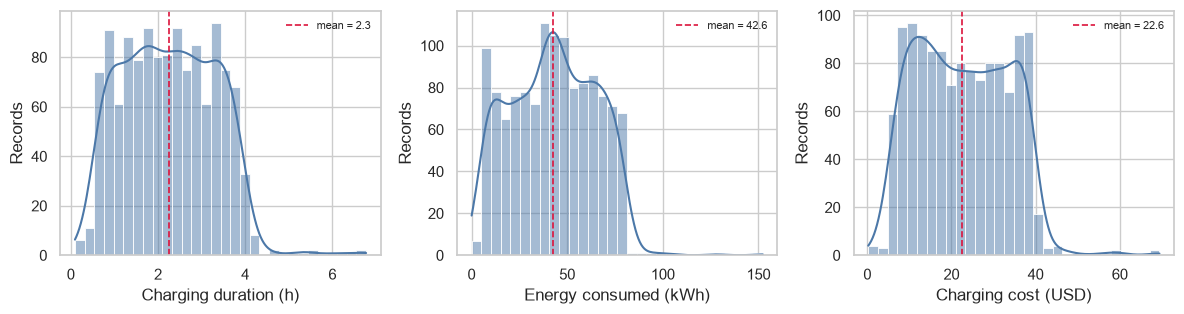

In [10]:
# Figure 1: distributions
fig, ax = plt.subplots(1, 3, figsize=(12, 3.3))
for a, (c, lab) in zip(ax, [('Duration_h','Charging duration (h)'),('Energy_kWh','Energy consumed (kWh)'),('Cost_USD','Charging cost (USD)')]):
    sns.histplot(df[c], bins=30, kde=True, color='#4C78A8', ax=a)
    a.axvline(df[c].mean(), color='crimson', ls='--', lw=1.2, label=f'mean = {df[c].mean():.1f}')
    a.set_xlabel(lab); a.set_ylabel('Records'); a.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig('figs/fig1_distributions.png', dpi=200); plt.show()

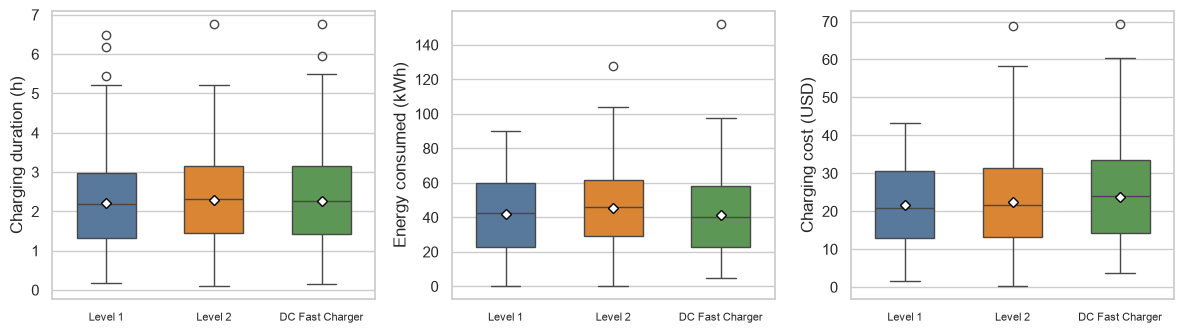

In [11]:
# Figure 2: box plots by charger type
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
for a, (c, lab) in zip(ax, [('Duration_h','Charging duration (h)'),('Energy_kWh','Energy consumed (kWh)'),('Cost_USD','Charging cost (USD)')]):
    sns.boxplot(data=df, x='Charger', y=c, order=ORDER, palette=PAL, width=.55, showmeans=True,
                meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor='black', markersize=5), ax=a)
    a.set_xlabel(''); a.set_ylabel(lab); a.tick_params(axis='x', labelsize=8)
plt.tight_layout(); plt.savefig('figs/fig2_boxplots.png', dpi=200); plt.show()

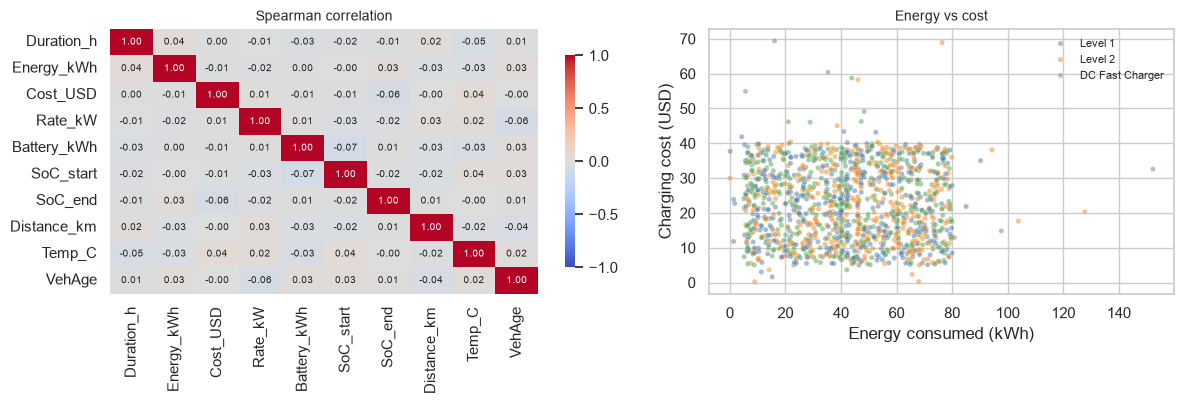

Spearman energy-cost: SignificanceResult(statistic=np.float64(-0.014534596317714652), pvalue=np.float64(0.605529072220599))
Spearman energy-duration: SignificanceResult(statistic=np.float64(0.03820596510705118), pvalue=np.float64(0.17445802209135447))


In [12]:
# Figure 3: relationships (correlation heatmap + energy vs cost scatter)
num = ['Duration_h','Energy_kWh','Cost_USD','Rate_kW','Battery_kWh','SoC_start','SoC_end','Distance_km','Temp_C','VehAge']
corr = df[num].corr(method='spearman')
R['max_abs_corr_core'] = float(corr.loc[core].drop(columns=core).abs().max().max())
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios':[1.15,1]})
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, annot_kws={'size':7}, cbar_kws={'shrink':.8}, ax=ax[0])
ax[0].set_title('Spearman correlation', fontsize=10)
sns.scatterplot(data=df, x='Energy_kWh', y='Cost_USD', hue='Charger', hue_order=ORDER, palette=PAL, alpha=.5, s=14, ax=ax[1])
ax[1].set_xlabel('Energy consumed (kWh)'); ax[1].set_ylabel('Charging cost (USD)'); ax[1].legend(frameon=False, fontsize=8)
ax[1].set_title('Energy vs cost', fontsize=10)
plt.tight_layout(); plt.savefig('figs/fig3_relationships.png', dpi=200); plt.show()
r_ec = stats.spearmanr(df.Energy_kWh, df.Cost_USD); r_ed = stats.spearmanr(df.Energy_kWh, df.Duration_h)
R['rho_energy_cost'] = [float(r_ec[0]), float(r_ec[1])]; R['rho_energy_dur'] = [float(r_ed[0]), float(r_ed[1])]
print('Spearman energy-cost:', r_ec); print('Spearman energy-duration:', r_ed)

Charger
Level 1            0.536
Level 2            0.501
DC Fast Charger    0.582
Name: Cost_per_kWh, dtype: float64


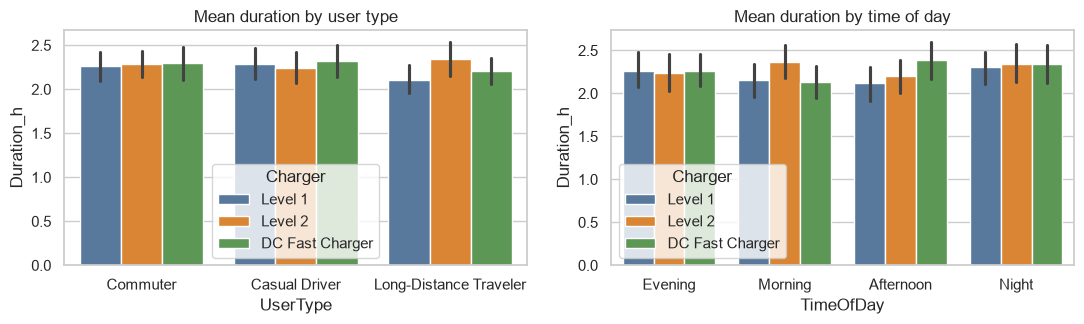

In [13]:
# mean cost per kWh, duration by charger split by user type / time of day
df['Cost_per_kWh'] = df.Cost_USD / df.Energy_kWh
print(df.groupby('Charger', observed=True)['Cost_per_kWh'].median().round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
sns.barplot(data=df, x='UserType', y='Duration_h', hue='Charger', hue_order=ORDER, palette=PAL, errorbar='ci', ax=ax[0]); ax[0].set_title('Mean duration by user type')
sns.barplot(data=df, x='TimeOfDay', y='Duration_h', hue='Charger', hue_order=ORDER, palette=PAL, errorbar='ci', ax=ax[1]); ax[1].set_title('Mean duration by time of day')
plt.tight_layout(); plt.savefig('figs/fig_extra_groups.png', dpi=200); plt.show()

## 4. Confirmatory Data Analysis (CDA)
**Research question:** Does mean charging duration differ between charger types?

- H0: μ(Level 1) = μ(Level 2) = μ(DC Fast)
- H1: at least one charger type has a different mean duration
- α = 0.05

In [14]:
groups = {g: df.loc[df.Charger==g, 'Duration_h'].values for g in ORDER}
# Assumption checks
sh = {g: stats.shapiro(v) for g, v in groups.items()}
for g,(w,p) in sh.items(): print(f'Shapiro-Wilk {g:16s} W={w:.4f} p={p:.4g}  n={len(groups[g])}')
lev = stats.levene(*groups.values(), center='median')
print(f'Levene (median)  W={lev.statistic:.4f} p={lev.pvalue:.4g}')
R['shapiro'] = {g:[float(w), float(p)] for g,(w,p) in sh.items()}
R['levene'] = [float(lev.statistic), float(lev.pvalue)]

Shapiro-Wilk Level 1          W=0.9678 p=2.788e-08  n=442
Shapiro-Wilk Level 2          W=0.9691 p=1.305e-07  n=410
Shapiro-Wilk DC Fast Charger  W=0.9680 p=7.425e-08  n=413
Levene (median)  W=0.0641 p=0.9379


In [23]:
# One-way ANOVA (primary) + Kruskal-Wallis (robustness)
aov = stats.f_oneway(*groups.values())
N = len(df); k = 3
ss_between = sum(len(v)*(v.mean()-df.Duration_h.mean())**2 for v in groups.values())
ss_total = ((df.Duration_h-df.Duration_h.mean())**2).sum()
eta2 = ss_between/ss_total
kw = stats.kruskal(*groups.values())
eps2 = max(0.0, (kw.statistic - k + 1)/(N - k))
print(f'ANOVA   F({k-1},{N-k}) = {aov.statistic:.4f}, p = {aov.pvalue:.4f}, eta^2 = {eta2:.5f}')
print(f'Kruskal H({k-1}) = {kw.statistic:.4f}, p = {kw.pvalue:.4f}, epsilon^2 = {eps2:.5f}')
R['anova'] = dict(F=float(aov.statistic), p=float(aov.pvalue), df1=k-1, df2=N-k, eta2=float(eta2))
R['kruskal'] = dict(H=float(kw.statistic), p=float(kw.pvalue), eps2=float(eps2))

ANOVA   F(2,1262) = 0.5425, p = 0.5815, eta^2 = 0.00086
Kruskal H(2) = 1.5162, p = 0.4686, epsilon^2 = 0.00000


     Multiple Comparison of Means - Tukey HSD, FWER=0.05     
     group1      group2 meandiff p-adj   lower  upper  reject
-------------------------------------------------------------
DC Fast Charger Level 1  -0.0573  0.706 -0.2262 0.1117  False
DC Fast Charger Level 2   0.0129  0.983 -0.1592  0.185  False
        Level 1 Level 2   0.0702 0.5942 -0.0991 0.2394  False
-------------------------------------------------------------
Level 1          mean=2.218  95% CI [2.118, 2.317]
Level 2          mean=2.288  95% CI [2.187, 2.389]
DC Fast Charger  mean=2.275  95% CI [2.173, 2.377]


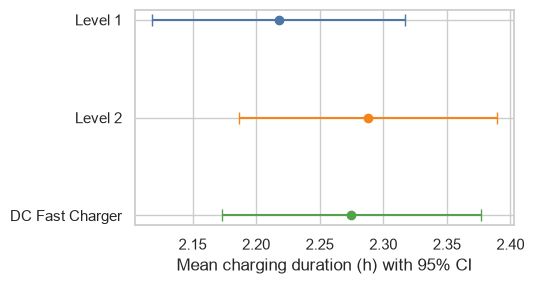

In [16]:
# Post-hoc (Tukey HSD) and group means with 95% CI
tk = pairwise_tukeyhsd(df.Duration_h, df.Charger.astype(str), alpha=0.05)
print(tk.summary())
R['tukey'] = [dict(g1=r[0], g2=r[1], diff=float(r[2]), p=float(r[3]), lo=float(r[4]), hi=float(r[5]), reject=bool(r[6])) for r in tk._results_table.data[1:]]
ci = {}
for g,v in groups.items():
    m, se = v.mean(), stats.sem(v); h = se*stats.t.ppf(.975, len(v)-1)
    ci[g] = [float(m), float(m-h), float(m+h)]
    print(f'{g:16s} mean={m:.3f}  95% CI [{m-h:.3f}, {m+h:.3f}]')
R['ci'] = ci
fig, ax = plt.subplots(figsize=(5.5,3))
for i,g in enumerate(ORDER):
    m,lo,hi = ci[g]; ax.errorbar(m, i, xerr=[[m-lo],[hi-m]], fmt='o', color=PAL[g], capsize=4)
ax.set_yticks(range(3)); ax.set_yticklabels(ORDER); ax.set_xlabel('Mean charging duration (h) with 95% CI'); ax.invert_yaxis()
plt.tight_layout(); plt.savefig('figs/fig4_ci.png', dpi=200); plt.show()

In [24]:
def run(sub, label):
    g = [sub.loc[sub.Charger==c,'Duration_h'] for c in ORDER]
    a = stats.f_oneway(*g); h = stats.kruskal(*g)
    print(f'{label:34s} n={len(sub):4d}  ANOVA p={a.pvalue:.4f}  Kruskal p={h.pvalue:.4f}')
    return dict(n=len(sub), anova_p=float(a.pvalue), kw_p=float(h.pvalue))
R['sens'] = {}
R['sens']['strict']  = run(df[df.strict_ok], 'Strict subset (no SoC/energy flags)')
R['sens']['no_out']  = run(df[~df.flag_dur_outlier], 'Duration outliers (IQR) removed')
R['sens']['raw']     = run(raw.rename(columns=rename).assign(Charger=lambda d: d.Charger).dropna(subset=['Duration_h']), 'Raw data, no cleaning')
R['sens']['non_imp'] = run(df[~df.Energy_kWh_imputed], 'Excluding imputed-energy rows')

Strict subset (no SoC/energy flags) n= 874  ANOVA p=0.5381  Kruskal p=0.4727
Duration outliers (IQR) removed    n=1260  ANOVA p=0.5148  Kruskal p=0.4416
Raw data, no cleaning              n=1320  ANOVA p=0.8032  Kruskal p=0.5920
Excluding imputed-energy rows      n=1202  ANOVA p=0.5625  Kruskal p=0.4409


## 5. Association Rule Mining (ARM)
**Objective:** find frequently co-occurring combinations of charging characteristics.
**Method:** Apriori on one-hot "transactions" – each charging session is a basket of categorical items. Numeric variables (duration, energy, cost) are discretised into equal-frequency tertiles (Low/Medium/High).

In [19]:
t = pd.DataFrame(index=df.index)
t['Charger']   = 'Charger=' + df.Charger.astype(str)
t['User']      = 'User=' + df.UserType
t['Time']      = 'Time=' + df.TimeOfDay
t['City']      = 'City=' + df.City
t['Model']     = 'Model=' + df.Model
t['Weekend']   = np.where(df.Day.isin(['Saturday','Sunday']), 'Day=Weekend', 'Day=Weekday')
for c, n in [('Duration_h','Duration'), ('Energy_kWh','Energy'), ('Cost_USD','Cost')]:
    t[n] = n + '=' + pd.qcut(df[c], 3, labels=['Low','Medium','High']).astype(str)
basket = pd.get_dummies(t.stack()).groupby(level=0).max().astype(bool)
print('Transactions x items:', basket.shape)

MIN_SUP, MIN_CONF, MIN_LIFT = 0.04, 0.40, 1.10
fi = apriori(basket, min_support=MIN_SUP, use_colnames=True, max_len=3)
fi['k'] = fi.itemsets.apply(len)
print('Frequent itemsets:', fi.k.value_counts().sort_index().to_dict())
R['arm_params'] = dict(sup=MIN_SUP, conf=MIN_CONF, lift=MIN_LIFT, n_items=basket.shape[1], n_itemsets=len(fi))
R['arm_itemsets_by_k'] = {int(k):int(v) for k,v in fi.k.value_counts().sort_index().items()}
display(fi[fi.k>=2].sort_values('support', ascending=False).head(10))

Transactions x items: (1265, 31)
Frequent itemsets: {1: 31, 2: 410, 3: 380}


,support,itemsets,k
294,0.247431,"frozenset({Day=Weekday, User=Commuter})",2
278,0.241107,"frozenset({Day=Weekday, Duration=High})",2
67,0.240316,"frozenset({Day=Weekday, Charger=Level 1})",2
218,0.238735,"frozenset({Day=Weekday, Cost=High})",2
281,0.235573,"frozenset({Day=Weekday, Energy=High})",2
95,0.232411,"frozenset({Day=Weekday, Charger=Level 2})",2
295,0.230830,"frozenset({User=Long-Distance Traveler, Day=We...",2
282,0.230830,"frozenset({Day=Weekday, Energy=Low})",2
258,0.230040,"frozenset({Cost=Medium, Day=Weekday})",2
283,0.229249,"frozenset({Day=Weekday, Energy=Medium})",2


In [20]:
rules = association_rules(fi, metric='confidence', min_threshold=MIN_CONF)
rules['ant'] = rules.antecedents.apply(lambda s: ' & '.join(sorted(s)))
rules['con'] = rules.consequents.apply(lambda s: ' & '.join(sorted(s)))
R['arm_rules_conf'] = len(rules)
sel = rules[(rules.lift >= MIN_LIFT) & (rules.consequents.apply(len)==1)].sort_values('lift', ascending=False)
R['arm_rules_sel'] = len(sel)
print(f'Rules with conf >= {MIN_CONF}: {len(rules)};  with lift >= {MIN_LIFT} (single consequent): {len(sel)}')
display(sel[['ant','con','support','confidence','lift']].head(15).round(3))
# Targeted: what is associated with LONG duration / HIGH cost?
tgt = sel[sel.con.isin(['Duration=High','Cost=High','Energy=High'])]
display(tgt[['ant','con','support','confidence','lift']].head(10).round(3))
R['arm_top'] = sel[['ant','con','support','confidence','lift']].head(8).round(3).to_dict('records')
R['arm_max_lift'] = float(rules.lift.max()) if len(rules) else None
R['arm_charger_rules'] = rules[rules.ant.str.contains('Charger=') | rules.con.str.contains('Charger=')][['ant','con','support','confidence','lift']].sort_values('lift', ascending=False).head(5).round(3).to_dict('records')

Rules with conf >= 0.4: 383;  with lift >= 1.1 (single consequent): 81


,ant,con,support,confidence,lift
143,Charger=Level 2 & Energy=Low,User=Commuter,0.049,0.521,1.458
375,Duration=High & Time=Evening,Energy=High,0.042,0.465,1.394
69,Charger=DC Fast Charger & Duration=Medium,User=Long-Distance Traveler,0.051,0.461,1.382
142,Charger=Level 2 & User=Casual Driver,Energy=High,0.044,0.459,1.376
43,Cost=High & User=Casual Driver,Charger=DC Fast Charger,0.047,0.440,1.349
67,Charger=DC Fast Charger & User=Long-Distance T...,Duration=Medium,0.051,0.448,1.347
376,Energy=High & Time=Evening,Duration=High,0.042,0.449,1.346
42,Charger=DC Fast Charger & User=Casual Driver,Cost=High,0.047,0.440,1.320
261,Cost=Medium & Duration=Medium,Energy=Low,0.045,0.432,1.294
41,Cost=High & Energy=Low,Charger=DC Fast Charger,0.045,0.422,1.293


,ant,con,support,confidence,lift
375,Duration=High & Time=Evening,Energy=High,0.042,0.465,1.394
142,Charger=Level 2 & User=Casual Driver,Energy=High,0.044,0.459,1.376
376,Energy=High & Time=Evening,Duration=High,0.042,0.449,1.346
42,Charger=DC Fast Charger & User=Casual Driver,Cost=High,0.047,0.440,1.320
377,Duration=High & User=Casual Driver,Energy=High,0.047,0.429,1.285
378,Energy=High & User=Casual Driver,Duration=High,0.047,0.423,1.267
137,Charger=Level 2 & Duration=High,Energy=High,0.047,0.420,1.258
379,Duration=High & User=Long-Distance Traveler,Energy=High,0.041,0.416,1.247
144,City=Chicago & Day=Weekday,Cost=High,0.051,0.414,1.241
266,Day=Weekday & Model=Chevy Bolt,Duration=High,0.061,0.414,1.241


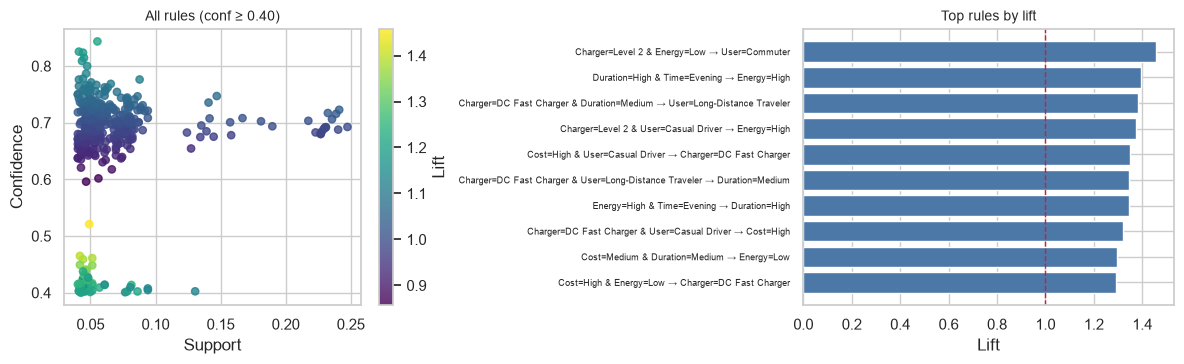

In [ ]:
# Figure 5: support-confidence scatter coloured by lift and top rules
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
sc = ax[0].scatter(rules.support, rules.confidence, c=rules.lift, cmap='viridis', s=28, alpha=.8)
plt.colorbar(sc, ax=ax[0], label='Lift'); ax[0].set_xlabel('Support'); ax[0].set_ylabel('Confidence'); ax[0].set_title('All rules (conf ≥ %.2f)' % MIN_CONF, fontsize=10)
top = sel.head(10).iloc[::-1]
ax[1].barh([f'{a} → {c}' for a, c in zip(top.ant, top.con)], top.lift, color='#4C78A8')
ax[1].axvline(1, color='crimson', ls='--', lw=1); ax[1].set_xlabel('Lift'); ax[1].tick_params(axis='y', labelsize=6.5); ax[1].set_title('Top rules by lift', fontsize=10)
plt.tight_layout(); plt.savefig('figs/fig5_arm.png', dpi=200); plt.show()

## 6. Save results for the report

In [22]:
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o
json.dump(clean(R), open('results.json','w'), indent=1)
print(json.dumps(clean(R), indent=1)[:1500])

{
 "n_raw": 1320,
 "p_raw": 20,
 "dups": 0,
 "missing": {
  "Energy_kWh": 66,
  "Rate_kW": 66,
  "Distance_km": 66
 },
 "invalid": {
  "SoC > 100 %": 32,
  "Temperature > 45 C (US cities)": 8,
  "Battery capacity < 20 or > 150 kWh": 16
 },
 "invalid_total": 55,
 "flags": {
  "flag_soc_drop": 256,
  "flag_energy_gt_cap": 175,
  "flag_time_mismatch": 1096,
  "flag_dur_outlier": 5,
  "flag_tod_mismatch": 961
 },
 "strict_n": 874,
 "n_clean": 1265,
 "n_vars_final": 32,
 "desc": {
  "Duration_h": {
   "count": 1265.0,
   "mean": 2.26,
   "median": 2.24,
   "std": 1.05,
   "min": 0.1,
   "max": 6.77
  },
  "Energy_kWh": {
   "count": 1265.0,
   "mean": 42.65,
   "median": 42.29,
   "std": 21.94,
   "min": 0.05,
   "max": 152.24
  },
  "Cost_USD": {
   "count": 1265.0,
   "mean": 22.6,
   "median": 22.21,
   "std": 10.75,
   "min": 0.23,
   "max": 69.41
  }
 },
 "by": {
  "Level 1": {
   "Duration_h": {
    "count": 442.0,
    "mean": 2.22,
    "median": 2.18,
    "std": 1.06
   },
   "Energy